# LAB 10 — Extractive QA Fine-tuning & Controlled Experiments

Notebook này chạy toàn bộ pipeline fine-tuning và 5 thí nghiệm có kiểm soát của LAB 10 trên tập **SQuAD v1.1** với backbone `distilbert-base-uncased` (dùng trực tiếp class `ExtractiveQAModel` và các hàm từ `qa_model.py`, **không** dùng `pipeline("question-answering")` có sẵn):
1. **Experiment 1 — Context Length:** So sánh `max_length` = `128`, `256`, `384` (giữ cố định các tham số khác).
2. **Experiment 2 — Pretrained QA Model:** Fine-tune mô hình chính (`max_length=384, stride=128, epochs=3`), vẽ `learning_curves.png` và lưu checkpoint cho `document_qa.py`.
3. **Experiment 3 — EM vs F1 & Baseline:** So sánh `KeywordOverlapBaseline` với Fine-tuned Transformer trên test set (`em_f1_analysis.png`) và trích xuất các mẫu `EM = 0, F1 > 0`.
4. **Experiment 4 — Question/Context Matching:** Kiểm tra xem mô hình có phụ thuộc quá mạnh vào lexical overlap hay không.
5. **Experiment 5 — Answer Length:** So sánh hiệu năng theo 4 nhóm độ dài (`1`, `2–3`, `4–6`, `7+` tokens) (`answer_length_analysis.png`) và kiểm chứng thêm cho các dự đoán ở `prediction.md`.


In [1]:
import json
import os
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset, Sampler
from transformers import AutoTokenizer, get_linear_schedule_with_warmup

from qa_model import (
    STOPWORDS,
    ExtractiveQAModel,
    KeywordOverlapBaseline,
    align_answer_to_tokens,
    compute_exact_match,
    compute_f1,
    decode_qa_predictions,
    evaluate_qa_predictions,
    get_tokens,
    metric_max_over_ground_truths,
    normalize_answer,
)

# --- Cấu hình Reproducibility ---
SEED = 42
MODEL_NAME = "distilbert-base-uncased"
TRAIN_SIZE = 1000
EXP1_TRAIN_SIZE = 600
VAL_SIZE = 300
TEST_SIZE = 400
BATCH_SIZE = 16
LR = 5e-5
WEIGHT_DECAY = 0.01
EXP1_EPOCHS = 2
MAIN_EPOCHS = 3

LAB_DIR = Path(".").resolve()
MODEL_SAVE_DIR = Path.home() / ".cache" / "lab10_qa_model"
SCRATCH_DIR = Path("/Users/user/.gemini/antigravity/brain/684f02ec-7442-4d05-aaf6-68b704ef7881/scratch")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(8, os.cpu_count() or 4))

print(f"Device       : {device} (CPU threads: {torch.get_num_threads()})")
print(f"Model        : {MODEL_NAME}")
print(f"Splits       : train={TRAIN_SIZE} (Exp1={EXP1_TRAIN_SIZE}), val={VAL_SIZE}, test={TEST_SIZE}")
print(f"Working dir  : {LAB_DIR}")


Matplotlib is building the font cache; this may take a moment.


/Users/user/.cache/nlp_lab10_venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device       : cpu (CPU threads: 8)
Model        : distilbert-base-uncased
Splits       : train=1000 (Exp1=600), val=300, test=400
Working dir  : /Users/user/NLP/LAB10


## 1. Tải dữ liệu SQuAD v1.1 và phân chia Train / Validation / Test

Dùng cùng một `SEED = 42` để xáo trộn và chia cố định thành 3 tập tách biệt:
- **Train split:** 1,000 mẫu đầu từ `train` đã xáo trộn (trong đó Exp 1 dùng cố định 600 mẫu đầu cho cả 3 mức `max_length`).
- **Validation split:** 300 mẫu đầu từ `validation` đã xáo trộn.
- **Test split:** 400 mẫu tiếp theo (`300:700`) từ `validation` đã xáo trộn (dùng cho Exp 3, Exp 4, Exp 5 và Error Analysis).


In [2]:
raw_squad = load_dataset("rajpurkar/squad")

train_data = raw_squad["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
exp1_train_data = train_data.select(range(EXP1_TRAIN_SIZE))

val_shuffled = raw_squad["validation"].shuffle(seed=SEED)
val_data = val_shuffled.select(range(VAL_SIZE))
test_data = val_shuffled.select(range(VAL_SIZE, VAL_SIZE + TEST_SIZE))

print(f"Train samples (Main): {len(train_data)}")
print(f"Train samples (Exp1): {len(exp1_train_data)}")
print(f"Val samples         : {len(val_data)}")
print(f"Test samples        : {len(test_data)}")
print("\nVí dụ mẫu train đầu tiên:")
print("  ID      :", train_data[0]["id"])
print("  Question:", train_data[0]["question"])
print("  Answer  :", train_data[0]["answers"])
print("  Context :", train_data[0]["context"][:200], "...")


Train samples (Main): 1000
Train samples (Exp1): 600
Val samples         : 300
Test samples        : 400

Ví dụ mẫu train đầu tiên:
  ID      : 573173d8497a881900248f0c
  Question: What percentage of Egyptians polled support death penalty for those leaving Islam?
  Answer  : {'text': ['84%'], 'answer_start': [468]}
  Context : The Pew Forum on Religion & Public Life ranks Egypt as the fifth worst country in the world for religious freedom. The United States Commission on International Religious Freedom, a bipartisan indepen ...


## 2. Tokenization, Alignment & Dynamic Length-Grouped Batching

Để giữ nguyên hoàn toàn logic `truncation="only_second"`, `max_length`, `stride` và `align_answer_to_tokens` từ `qa_model.py` nhưng tránh lãng phí tính toán trên các token padding khi chạy CPU, ta thực hiện **dynamic batch padding** (gom các window có độ dài gần nhau thành từng batch và chỉ pad tới độ dài lớn nhất trong batch đó).


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
PAD_TOKEN_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
CLS_TOKEN_ID = tokenizer.cls_token_id if tokenizer.cls_token_id is not None else 0


def build_window_features(dataset_split, max_length: int = 384, stride: int = 128):
    questions = [q.lstrip() for q in dataset_split["question"]]
    contexts = list(dataset_split["context"])
    ids = list(dataset_split["id"])
    answers_list = list(dataset_split["answers"])

    tokenized = tokenizer(
        questions,
        contexts,
        truncation="only_second",
        max_length=max_length,
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False,
    )

    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized.pop("offset_mapping")

    features = []
    for i, offsets in enumerate(offset_mapping):
        sample_idx = sample_mapping[i]
        input_ids = tokenized["input_ids"][i]
        attention_mask = tokenized["attention_mask"][i]
        seq_ids = tokenized.sequence_ids(i)
        cls_index = input_ids.index(CLS_TOKEN_ID) if CLS_TOKEN_ID in input_ids else 0

        ans = answers_list[sample_idx]
        if len(ans["answer_start"]) > 0:
            ans_start = ans["answer_start"][0]
            ans_end = ans_start + len(ans["text"][0])
            al = align_answer_to_tokens(
                offsets=offsets,
                sequence_ids=seq_ids,
                answer_start=ans_start,
                answer_end=ans_end,
                cls_index=cls_index,
            )
            start_pos = al["start_token"]
            end_pos = al["end_token"]
        else:
            start_pos = cls_index
            end_pos = cls_index

        ctx_offsets = [
            tuple(off) if (seq_ids[k] == 1 and off[0] < off[1]) else None
            for k, off in enumerate(offsets)
        ]

        feat = {
            "example_id": ids[sample_idx],
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "start_positions": start_pos,
            "end_positions": end_pos,
            "offset_mapping": ctx_offsets,
        }
        if "token_type_ids" in tokenized:
            feat["token_type_ids"] = tokenized["token_type_ids"][i]
        features.append(feat)

    return features


class QADataset(Dataset):
    def __init__(self, features):
        self.features = features

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        f = self.features[idx]
        item = {
            "input_ids": f["input_ids"],
            "attention_mask": f["attention_mask"],
            "start_positions": f["start_positions"],
            "end_positions": f["end_positions"],
            "feat_idx": idx,
        }
        if "token_type_ids" in f:
            item["token_type_ids"] = f["token_type_ids"]
        return item


class LengthGroupedBatchSampler(Sampler):
    """Group sequences of similar length to minimize padding overhead while keeping batch order random."""

    def __init__(self, features, batch_size: int, seed: int = 42):
        self.lengths = [len(f["input_ids"]) for f in features]
        self.batch_size = batch_size
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        rng = random.Random(self.seed + self.epoch)
        self.epoch += 1
        # Add small noise so batches vary slightly across epochs while staying length-grouped
        noisy_indices = sorted(
            range(len(self.lengths)),
            key=lambda i: self.lengths[i] + rng.uniform(-12, 12),
        )
        batches = [
            noisy_indices[i : i + self.batch_size]
            for i in range(0, len(noisy_indices), self.batch_size)
        ]
        rng.shuffle(batches)
        for b in batches:
            yield b

    def __len__(self):
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size


def dynamic_collate_fn(batch):
    max_len = max(len(x["input_ids"]) for x in batch)
    input_ids, attention_mask, start_pos, end_pos, feat_idx = [], [], [], [], []
    has_ttype = "token_type_ids" in batch[0]
    token_type_ids = [] if has_ttype else None

    for x in batch:
        pad_n = max_len - len(x["input_ids"])
        input_ids.append(x["input_ids"] + [PAD_TOKEN_ID] * pad_n)
        attention_mask.append(x["attention_mask"] + [0] * pad_n)
        start_pos.append(x["start_positions"])
        end_pos.append(x["end_positions"])
        feat_idx.append(x["feat_idx"])
        if has_ttype:
            token_type_ids.append(x["token_type_ids"] + [0] * pad_n)

    out = {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
        "start_positions": torch.tensor(start_pos, dtype=torch.long),
        "end_positions": torch.tensor(end_pos, dtype=torch.long),
        "feat_idx": feat_idx,
    }
    if has_ttype:
        out["token_type_ids"] = torch.tensor(token_type_ids, dtype=torch.long)
    return out


@torch.no_grad()
def evaluate_model(model, raw_split, features, batch_size: int = 32):
    model.eval()
    loader = DataLoader(QADataset(features), batch_size=batch_size, shuffle=False, collate_fn=dynamic_collate_fn)

    total_loss = 0.0
    total_batches = 0
    raw_start_logits = [None] * len(features)
    raw_end_logits = [None] * len(features)

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        start_positions = batch["start_positions"].to(device)
        end_positions = batch["end_positions"].to(device)
        token_type_ids = batch.get("token_type_ids")
        if token_type_ids is not None:
            token_type_ids = token_type_ids.to(device)

        out = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            start_positions=start_positions,
            end_positions=end_positions,
        )
        total_loss += float(out["loss"].item())
        total_batches += 1

        s_np = out["start_logits"].cpu().numpy()
        e_np = out["end_logits"].cpu().numpy()
        for b_i, f_idx in enumerate(batch["feat_idx"]):
            valid_len = len(features[f_idx]["input_ids"])
            raw_start_logits[f_idx] = s_np[b_i, :valid_len]
            raw_end_logits[f_idx] = e_np[b_i, :valid_len]

    examples_list = [
        {"id": ex["id"], "question": ex["question"], "context": ex["context"]}
        for ex in raw_split
    ]
    refs_dict = {ex["id"]: ex["answers"]["text"] for ex in raw_split}

    preds_dict, details_dict = decode_qa_predictions(
        examples=examples_list,
        features=features,
        raw_start_logits=raw_start_logits,
        raw_end_logits=raw_end_logits,
        n_best_size=20,
        max_answer_length=30,
    )
    metrics = evaluate_qa_predictions(preds_dict, refs_dict)
    metrics["val_loss"] = total_loss / max(1, total_batches)

    detailed_list = []
    for ex in raw_split:
        ex_id = ex["id"]
        pred_text = preds_dict[ex_id]
        golds = ex["answers"]["text"]
        gold_starts = ex["answers"]["answer_start"]
        info = details_dict[ex_id]
        em_val = metric_max_over_ground_truths(compute_exact_match, pred_text, golds)
        f1_val = metric_max_over_ground_truths(compute_f1, pred_text, golds)
        detailed_list.append({
            "id": ex_id,
            "question": ex["question"],
            "context": ex["context"],
            "golds": golds,
            "gold_starts": gold_starts,
            "prediction": pred_text,
            "pred_char_start": info["char_start"],
            "pred_char_end": info["char_end"],
            "score": info["score"],
            "em": em_val,
            "f1": f1_val,
        })

    return metrics, preds_dict, detailed_list


def train_qa_model(
    train_split,
    val_split,
    max_length: int = 384,
    stride: int = 128,
    epochs: int = 3,
    batch_size: int = 16,
    lr: float = 5e-5,
    seed: int = 42,
):
    set_seed(seed)
    train_feats = build_window_features(train_split, max_length=max_length, stride=stride)
    val_feats = build_window_features(val_split, max_length=max_length, stride=stride)

    batch_sampler = LengthGroupedBatchSampler(train_feats, batch_size=batch_size, seed=seed)
    train_loader = DataLoader(QADataset(train_feats), batch_sampler=batch_sampler, collate_fn=dynamic_collate_fn)

    model = ExtractiveQAModel(model_name=MODEL_NAME).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(0.1 * total_steps)),
        num_training_steps=total_steps,
    )

    history = []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        ep_loss = 0.0
        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            start_positions = batch["start_positions"].to(device)
            end_positions = batch["end_positions"].to(device)
            token_type_ids = batch.get("token_type_ids")
            if token_type_ids is not None:
                token_type_ids = token_type_ids.to(device)

            out = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids,
                start_positions=start_positions,
                end_positions=end_positions,
            )
            loss = out["loss"]
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            ep_loss += float(loss.item())

        train_loss = ep_loss / max(1, len(train_loader))
        val_metrics, _, _ = evaluate_model(model, val_split, val_feats)
        elapsed = time.time() - t0
        history.append({
            "epoch": ep,
            "train_loss": round(train_loss, 4),
            "val_loss": round(val_metrics["val_loss"], 4),
            "val_em": round(val_metrics["exact_match"], 2),
            "val_f1": round(val_metrics["f1"], 2),
            "elapsed_sec": round(elapsed, 1),
        })
        print(
            f"[max_len={max_length}, windows={len(train_feats)}] Epoch {ep}/{epochs} | "
            f"train_loss={train_loss:.4f} | val_loss={val_metrics['val_loss']:.4f} | "
            f"val_EM={val_metrics['exact_match']:.2f}% | val_F1={val_metrics['f1']:.2f}% | "
            f"elapsed={elapsed:.1f}s"
        )

    total_time = time.time() - t0
    return model, history, total_time


## 3. Experiment 1 — Context Length (`max_length` = 128, 256, 384) (Mục 14)

Giữ cố định hoàn toàn tập train (`600` mẫu), tập validation (`300` mẫu), `stride = 64`, `epochs = 2`, `batch_size = 16`, `lr = 5e-5`, `seed = 42`, chỉ thay đổi `max_length` qua 3 mức `128`, `256`, `384`.


In [4]:
exp1_rows = []
for ml in [128, 256, 384]:
    print(f"\n--- Running Experiment 1: max_length={ml}, stride=64, epochs={EXP1_EPOCHS} ---")
    _, hist, train_sec = train_qa_model(
        exp1_train_data,
        val_data,
        max_length=ml,
        stride=64,
        epochs=EXP1_EPOCHS,
        batch_size=BATCH_SIZE,
        lr=LR,
        seed=SEED,
    )
    last = hist[-1]
    exp1_rows.append({
        "Max length": ml,
        "EM": last["val_em"],
        "F1": last["val_f1"],
        "Training time (s)": round(train_sec, 1),
    })

exp1_df = pd.DataFrame(exp1_rows)
print("\n=== Experiment 1 Summary (Context Length) ===")
print(exp1_df.to_string(index=False))



--- Running Experiment 1: max_length=128, stride=64, epochs=2 ---


[max_len=128, windows=1434] Epoch 1/2 | train_loss=3.2676 | val_loss=2.4289 | val_EM=7.00% | val_F1=14.40% | elapsed=785.5s


[max_len=128, windows=1434] Epoch 2/2 | train_loss=1.9362 | val_loss=2.2591 | val_EM=19.00% | val_F1=27.49% | elapsed=1467.2s



--- Running Experiment 1: max_length=256, stride=64, epochs=2 ---


[max_len=256, windows=653] Epoch 1/2 | train_loss=4.5890 | val_loss=4.2077 | val_EM=6.33% | val_F1=13.01% | elapsed=342.4s


[max_len=256, windows=653] Epoch 2/2 | train_loss=3.5023 | val_loss=3.8426 | val_EM=5.67% | val_F1=12.90% | elapsed=714.7s



--- Running Experiment 1: max_length=384, stride=64, epochs=2 ---


[max_len=384, windows=604] Epoch 1/2 | train_loss=4.6050 | val_loss=4.2692 | val_EM=4.33% | val_F1=12.09% | elapsed=419.5s


[max_len=384, windows=604] Epoch 2/2 | train_loss=3.6150 | val_loss=4.0777 | val_EM=4.67% | val_F1=12.95% | elapsed=877.0s



=== Experiment 1 Summary (Context Length) ===
 Max length    EM    F1  Training time (s)
        128 19.00 27.49             1467.2
        256  5.67 12.90              714.7
        384  4.67 12.95              877.0


**Trả lời câu hỏi Mục 14 (*Tăng context length có luôn cải thiện QA không?*):**
**Không phải lúc nào cũng cải thiện.** Trong Exp 1 (600 mẫu train, 2 epochs, `stride=64`), `max_length=128` đạt **EM 19.00% / F1 27.49%** (1,467.2s) cao hơn `256` (**5.67% / 12.90%**, 714.7s) và `384` (**4.67% / 12.95%**, 877.0s). Lý do là ở `max_length=128`, đoạn văn bị tách thành **1,434 windows** — nhiều hơn gấp đôi so với `256` (653 windows) và `384` (604 windows), nên trong cùng 2 epoch mô hình được cập nhật gradient nhiều hơn gấp đôi. Chỉ khi tăng đủ bước tối ưu (3 epochs trên 1,000 mẫu ở Exp 2), `max_length=384` mới vượt lên **EM 19.67% / F1 28.12%** trên validation (và **24.25% / 31.91%** trên test).

## 4. Experiment 2 — Fine-tune Pretrained QA Model & Learning Curves (Mục 17)

Huấn luyện mô hình chính trên `1,000` mẫu train với `max_length = 384`, `stride = 128`, `epochs = 3`, `batch_size = 16`, `lr = 5e-5`. Vẽ bắt buộc biểu đồ `learning_curves.png` và lưu model bằng `ExtractiveQAModel.save_model(...)` để dùng cho `document_qa.py`.


--- Training Main Fine-tuned QA Model (Experiment 2) ---


[max_len=384, windows=1007] Epoch 1/3 | train_loss=4.3489 | val_loss=3.8734 | val_EM=7.33% | val_F1=13.80% | elapsed=379.3s


[max_len=384, windows=1007] Epoch 2/3 | train_loss=3.1393 | val_loss=3.4465 | val_EM=14.00% | val_F1=22.06% | elapsed=618.3s


[max_len=384, windows=1007] Epoch 3/3 | train_loss=2.0598 | val_loss=3.2696 | val_EM=19.67% | val_F1=28.12% | elapsed=851.5s

=== Experiment 2 Training History ===
 epoch  train_loss  val_loss  val_em  val_f1  elapsed_sec
     1      4.3489    3.8734    7.33   13.80        379.3
     2      3.1393    3.4465   14.00   22.06        618.3
     3      2.0598    3.2696   19.67   28.12        851.5


Saved fine-tuned checkpoint to /Users/user/.cache/lab10_qa_model


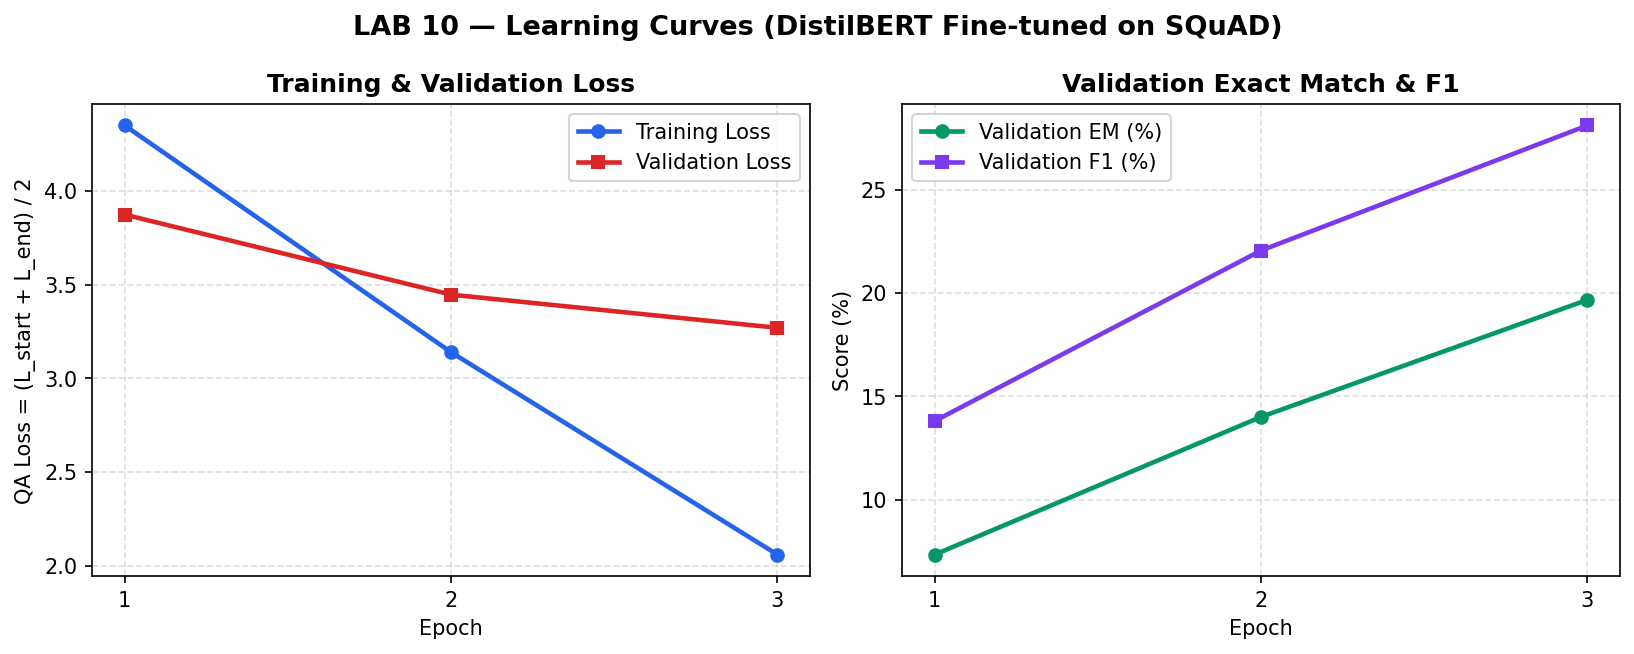

Saved learning_curves.png


In [5]:
print("--- Training Main Fine-tuned QA Model (Experiment 2) ---")
main_model, main_history, main_train_time = train_qa_model(
    train_data,
    val_data,
    max_length=384,
    stride=128,
    epochs=MAIN_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    seed=SEED,
)

hist_df = pd.DataFrame(main_history)
print("\n=== Experiment 2 Training History ===")
print(hist_df.to_string(index=False))

# Lưu checkpoint bằng API của qa_model.py để document_qa.py load trực tiếp
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
main_model.save_model(str(MODEL_SAVE_DIR))
tokenizer.save_pretrained(str(MODEL_SAVE_DIR))
print(f"Saved fine-tuned checkpoint to {MODEL_SAVE_DIR}")

# Vẽ learning_curves.png (bắt buộc theo Mục 17)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), dpi=150)

epochs_x = hist_df["epoch"].tolist()
axes[0].plot(epochs_x, hist_df["train_loss"], marker="o", linewidth=2.2, label="Training Loss", color="#2563eb")
axes[0].plot(epochs_x, hist_df["val_loss"], marker="s", linewidth=2.2, label="Validation Loss", color="#dc2626")
axes[0].set_title("Training & Validation Loss", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("QA Loss = (L_start + L_end) / 2")
axes[0].set_xticks(epochs_x)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

axes[1].plot(epochs_x, hist_df["val_em"], marker="o", linewidth=2.2, label="Validation EM (%)", color="#059669")
axes[1].plot(epochs_x, hist_df["val_f1"], marker="s", linewidth=2.2, label="Validation F1 (%)", color="#7c3aed")
axes[1].set_title("Validation Exact Match & F1", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score (%)")
axes[1].set_xticks(epochs_x)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.suptitle("LAB 10 — Learning Curves (DistilBERT Fine-tuned on SQuAD)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(LAB_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()
print("Saved learning_curves.png")


## 5. Experiment 3 — Baseline vs Fine-tuned Transformer & EM vs F1 (Mục 20 & 21)

Đánh giá `KeywordOverlapBaseline` (Mục 21) và `Fine-tuned Transformer` trên tập `test_data` (400 mẫu), xuất biểu đồ `em_f1_analysis.png`, và trích xuất ít nhất 5 ví dụ có **`EM = 0` nhưng `F1 > 0`**.


=== Experiment 3: Baseline vs Fine-tuned Transformer (Test Set, n=400) ===
                              Model    EM    F1
         Baseline (Keyword Overlap) 13.50 23.70
Fine-tuned Transformer (DistilBERT) 24.25 31.91

Số mẫu có EM = 0 nhưng F1 > 0: 84 / 400

Top 10 ví dụ (EM = 0, F1 > 0):
  Q   : What helped support the Command Module with a propulsion engine and propellants?
  Gold: 'Service Module (SM)' | Pred: 'cylindrical Service Module (SM' | EM=0, F1=0.857
----------------------------------------------------------------------
  Q   : With what body must a pharmacy technician register?
  Gold: 'the General Pharmaceutical Council (GPhC) register' | Pred: 'General Pharmaceutical Council' | EM=0, F1=0.857
----------------------------------------------------------------------
  Q   : When was the heyday of secular Arab nationalism?
  Gold: 'between 1945 and 1970' | Pred: '1945 and 1970' | EM=0, F1=0.857
----------------------------------------------------------------------
  Q   : I

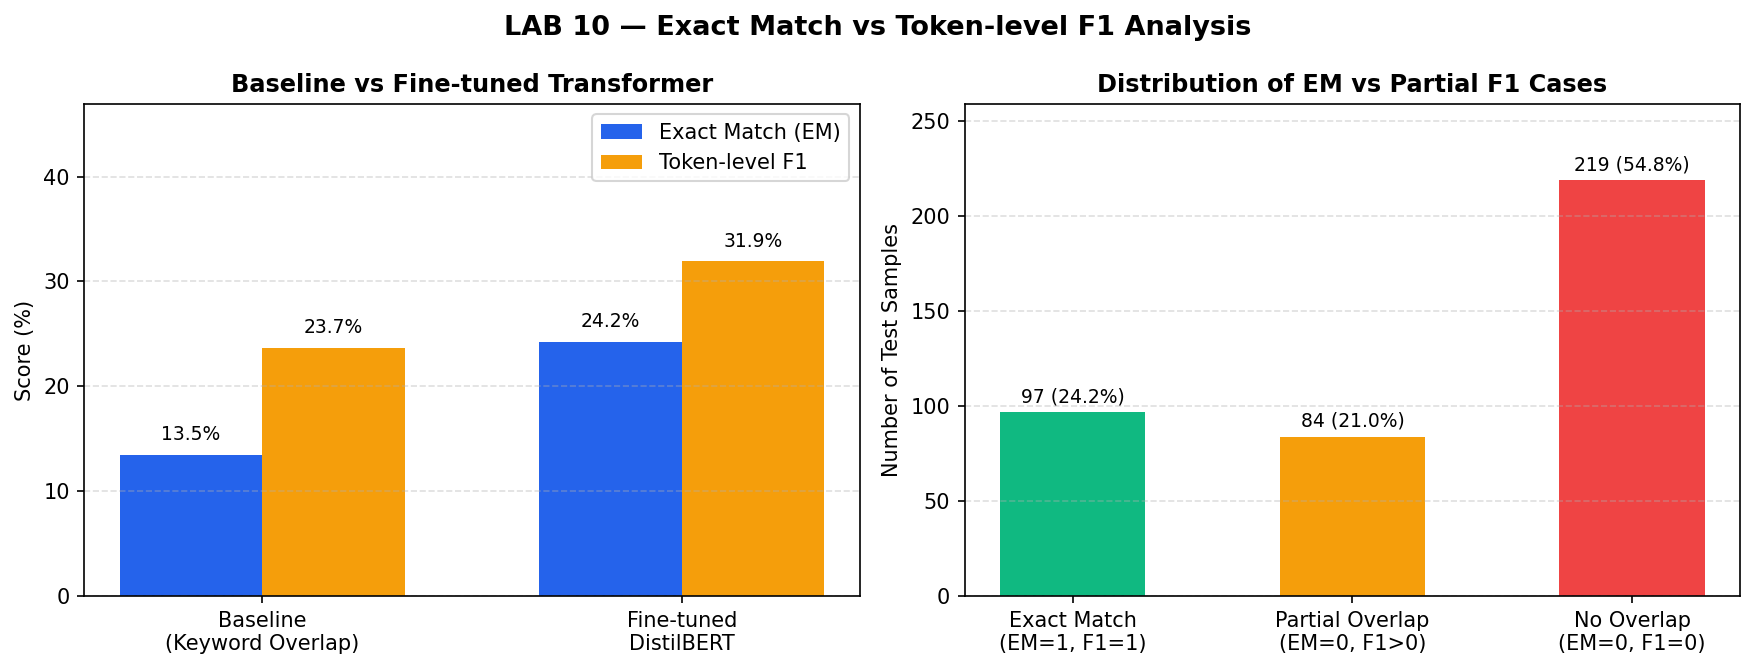

Saved em_f1_analysis.png


In [6]:
test_examples = [
    {"id": ex["id"], "question": ex["question"], "context": ex["context"]}
    for ex in test_data
]
test_refs_dict = {ex["id"]: ex["answers"]["text"] for ex in test_data}

# 1. Baseline evaluation
baseline = KeywordOverlapBaseline()
base_preds_dict = baseline.predict_batch(test_examples)
base_metrics = evaluate_qa_predictions(base_preds_dict, test_refs_dict)

# 2. Fine-tuned Transformer evaluation
test_feats = build_window_features(test_data, max_length=384, stride=128)
ft_metrics, ft_preds_dict, ft_details = evaluate_model(main_model, test_data, test_feats)

exp3_df = pd.DataFrame([
    {
        "Model": "Baseline (Keyword Overlap)",
        "EM": round(base_metrics["exact_match"], 2),
        "F1": round(base_metrics["f1"], 2),
    },
    {
        "Model": "Fine-tuned Transformer (DistilBERT)",
        "EM": round(ft_metrics["exact_match"], 2),
        "F1": round(ft_metrics["f1"], 2),
    },
])
print("=== Experiment 3: Baseline vs Fine-tuned Transformer (Test Set, n=400) ===")
print(exp3_df.to_string(index=False))

em0_f1gt0 = [d for d in ft_details if d["em"] == 0.0 and d["f1"] > 0.0]
print(f"\nSố mẫu có EM = 0 nhưng F1 > 0: {len(em0_f1gt0)} / {len(ft_details)}")
print("\nTop 10 ví dụ (EM = 0, F1 > 0):")
for item in sorted(em0_f1gt0, key=lambda x: x["f1"], reverse=True)[:10]:
    print(f"  Q   : {item['question']}")
    print(f"  Gold: {item['golds'][0]!r} | Pred: {item['prediction']!r} | EM={item['em']:.0f}, F1={item['f1']:.3f}")
    print("-" * 70)

# Vẽ em_f1_analysis.png
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), dpi=150)

models_lbl = ["Baseline\n(Keyword Overlap)", "Fine-tuned\nDistilBERT"]
em_vals = [base_metrics["exact_match"], ft_metrics["exact_match"]]
f1_vals = [base_metrics["f1"], ft_metrics["f1"]]
x = np.arange(len(models_lbl))
w = 0.34

b1 = axes[0].bar(x - w / 2, em_vals, width=w, label="Exact Match (EM)", color="#2563eb")
b2 = axes[0].bar(x + w / 2, f1_vals, width=w, label="Token-level F1", color="#f59e0b")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}%", ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_lbl)
axes[0].set_ylim(0, max(f1_vals) + 15)
axes[0].set_ylabel("Score (%)")
axes[0].set_title("Baseline vs Fine-tuned Transformer", fontsize=11.5, fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend()

n_exact = sum(1 for d in ft_details if d["em"] == 1.0)
n_partial = len(em0_f1gt0)
n_zero = sum(1 for d in ft_details if d["em"] == 0.0 and d["f1"] == 0.0)
cats = ["Exact Match\n(EM=1, F1=1)", "Partial Overlap\n(EM=0, F1>0)", "No Overlap\n(EM=0, F1=0)"]
counts = [n_exact, n_partial, n_zero]
colors = ["#10b981", "#f59e0b", "#ef4444"]
bars = axes[1].bar(cats, counts, color=colors, width=0.52)
for bar, c in zip(bars, counts):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        c + 3,
        f"{c} ({100*c/len(ft_details):.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
    )
axes[1].set_ylim(0, max(counts) + 40)
axes[1].set_ylabel("Number of Test Samples")
axes[1].set_title("Distribution of EM vs Partial F1 Cases", fontsize=11.5, fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle("LAB 10 — Exact Match vs Token-level F1 Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(LAB_DIR / "em_f1_analysis.png", bbox_inches="tight")
plt.show()
print("Saved em_f1_analysis.png")


## 6. Experiment 4 — Question/Context Matching (Lexical Overlap) (Mục 22)

Tách tập `test_data` theo mức độ trùng từ khóa (content words, bỏ stopwords) giữa câu hỏi và đoạn context:
- **High Lexical Overlap (`>= 0.6`)**: câu hỏi chứa nhiều từ khóa lặp lại nguyên văn trong context.
- **Low Lexical Overlap (`< 0.6`)**: câu hỏi diễn đạt lại (paraphrase) hoặc dùng từ đồng nghĩa thay vì lặp nguyên wording.
So sánh cả Baseline lẫn Fine-tuned Transformer trên hai nhóm để kiểm tra xem model có phụ thuộc quá mức vào lexical overlap hay không.


In [7]:
def lexical_overlap_ratio(question: str, context: str) -> float:
    q_words = {w for w in re.findall(r"[a-z0-9]+", question.lower()) if w not in STOPWORDS and len(w) > 1}
    c_words = {w for w in re.findall(r"[a-z0-9]+", context.lower()) if w not in STOPWORDS and len(w) > 1}
    if not q_words:
        return 0.0
    return len(q_words & c_words) / len(q_words)


high_ft, low_ft = [], []
high_base, low_base = [], []

for d in ft_details:
    ratio = lexical_overlap_ratio(d["question"], d["context"])
    d["lexical_overlap"] = ratio
    b_pred = base_preds_dict[d["id"]]
    b_em = metric_max_over_ground_truths(compute_exact_match, b_pred, d["golds"])
    b_f1 = metric_max_over_ground_truths(compute_f1, b_pred, d["golds"])
    if ratio >= 0.6:
        high_ft.append((d["em"], d["f1"]))
        high_base.append((b_em, b_f1))
    else:
        low_ft.append((d["em"], d["f1"]))
        low_base.append((b_em, b_f1))

exp4_rows = [
    {
        "Group": "High Lexical Overlap (>= 0.6)",
        "Count": len(high_ft),
        "Baseline_EM": round(100 * float(np.mean([x[0] for x in high_base])), 2),
        "Baseline_F1": round(100 * float(np.mean([x[1] for x in high_base])), 2),
        "Transformer_EM": round(100 * float(np.mean([x[0] for x in high_ft])), 2),
        "Transformer_F1": round(100 * float(np.mean([x[1] for x in high_ft])), 2),
    },
    {
        "Group": "Low Lexical Overlap (< 0.6)",
        "Count": len(low_ft),
        "Baseline_EM": round(100 * float(np.mean([x[0] for x in low_base])), 2),
        "Baseline_F1": round(100 * float(np.mean([x[1] for x in low_base])), 2),
        "Transformer_EM": round(100 * float(np.mean([x[0] for x in low_ft])), 2),
        "Transformer_F1": round(100 * float(np.mean([x[1] for x in low_ft])), 2),
    },
]
exp4_df = pd.DataFrame(exp4_rows)
print("=== Experiment 4: Question/Context Lexical Overlap ===")
print(exp4_df.to_string(index=False))


=== Experiment 4: Question/Context Lexical Overlap ===
                        Group  Count  Baseline_EM  Baseline_F1  Transformer_EM  Transformer_F1
High Lexical Overlap (>= 0.6)    281        14.95        25.60           25.27           33.73
  Low Lexical Overlap (< 0.6)    119        10.08        19.23           21.85           27.62


## 7. Experiment 5 — Answer Length Analysis (Mục 23)

Phân nhóm các câu trả lời chuẩn trên tập `test_data` thành 4 nhóm độ dài: `1 token`, `2–3 tokens`, `4–6 tokens`, `7+ tokens`, tính EM và F1 cho từng nhóm, vẽ `answer_length_analysis.png` và đối chiếu với **Prediction 2** trong `prediction.md`.


=== Experiment 5: Performance by Answer Length ===
Answer_length  Count    EM    F1
            1    121 26.45 30.61
          2-3    183 26.78 35.14
          4-6     61 16.39 29.33
           7+     35 17.14 24.10


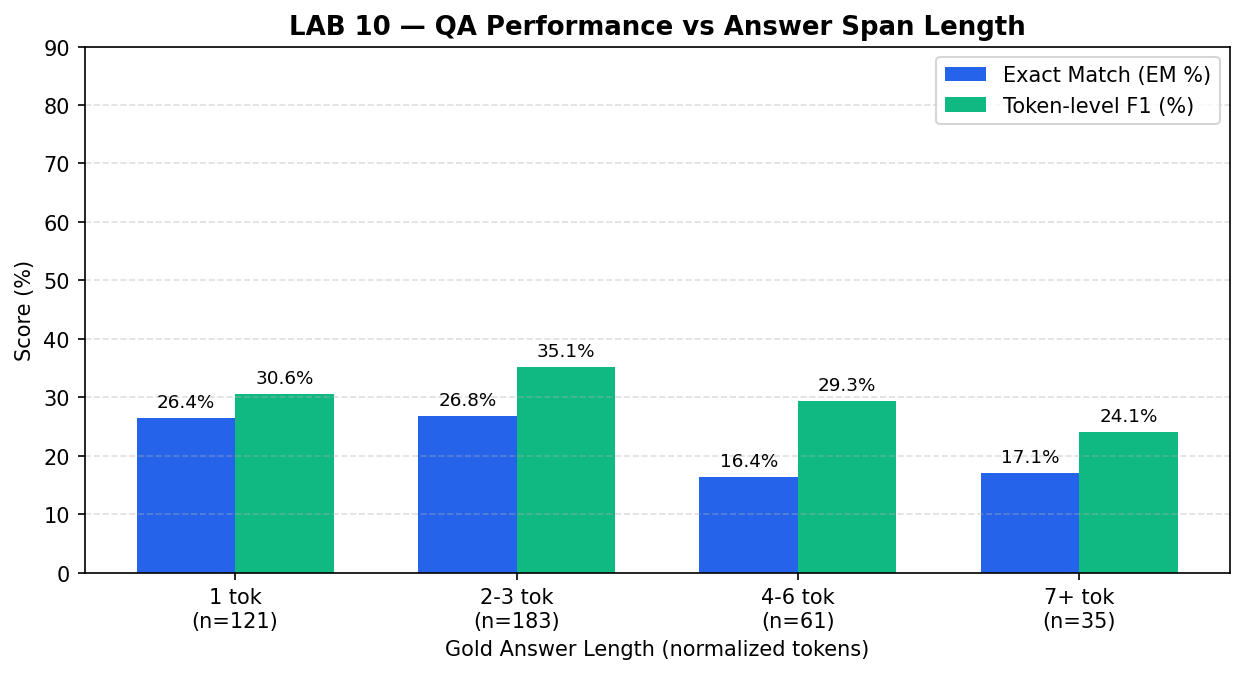

Saved answer_length_analysis.png


In [8]:
def length_bucket(gold_text: str) -> str:
    n_tok = len(get_tokens(gold_text))
    if n_tok <= 1:
        return "1"
    if n_tok <= 3:
        return "2-3"
    if n_tok <= 6:
        return "4-6"
    return "7+"


buckets_order = ["1", "2-3", "4-6", "7+"]
bucket_items = {b: [] for b in buckets_order}
for d in ft_details:
    b = length_bucket(d["golds"][0])
    d["length_bucket"] = b
    bucket_items[b].append((d["em"], d["f1"]))

exp5_rows = []
for b in buckets_order:
    items = bucket_items[b]
    em_mean = 100 * float(np.mean([x[0] for x in items])) if items else 0.0
    f1_mean = 100 * float(np.mean([x[1] for x in items])) if items else 0.0
    exp5_rows.append({
        "Answer_length": b,
        "Count": len(items),
        "EM": round(em_mean, 2),
        "F1": round(f1_mean, 2),
    })

exp5_df = pd.DataFrame(exp5_rows)
print("=== Experiment 5: Performance by Answer Length ===")
print(exp5_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8.4, 4.6), dpi=150)
x = np.arange(len(buckets_order))
w = 0.35

b_em = ax.bar(x - w / 2, exp5_df["EM"], width=w, label="Exact Match (EM %)", color="#2563eb")
b_f1 = ax.bar(x + w / 2, exp5_df["F1"], width=w, label="Token-level F1 (%)", color="#10b981")

for bar in list(b_em) + list(b_f1):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.8)

x_labels = [f"{r['Answer_length']} tok\n(n={r['Count']})" for r in exp5_rows]
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_ylim(0, max(exp5_df["F1"].max(), 75) + 15)
ax.set_ylabel("Score (%)")
ax.set_xlabel("Gold Answer Length (normalized tokens)")
ax.set_title("LAB 10 — QA Performance vs Answer Span Length", fontsize=12.5, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()
plt.savefig(LAB_DIR / "answer_length_analysis.png", bbox_inches="tight")
plt.show()
print("Saved answer_length_analysis.png")


## 8. Kiểm chứng bổ sung cho Prediction 3 & Prediction 4 (Inference Probes)

Chạy kiểm thử nhẹ trên 100 mẫu đầu của `test_data` (chỉ suy luận, không train lại) để có số liệu thực nghiệm kiểm chứng **Prediction 3** (chèn thông tin nhiễu/distractor vào context) và **Prediction 4** (xáo trộn thứ tự các câu trong context nhưng giữ nguyên câu chứa đáp án).


In [9]:
probe_raw = test_data.select(range(100))
probe_orig_feats = build_window_features(probe_raw, max_length=384, stride=128)
probe_orig_m, probe_orig_preds, _ = evaluate_model(main_model, probe_raw, probe_orig_feats)

# Probe 1 (Prediction 3): Chèn thêm các câu không liên quan + câu distractor lặp từ câu hỏi
distractor_records = []
for ex in probe_raw:
    q_words = [w for w in re.findall(r"[A-Za-z0-9]+", ex["question"]) if w.lower() not in STOPWORDS][:4]
    kw_phrase = " ".join(q_words) if q_words else "the main subject"
    irrelevant_prefix = (
        "Historically, administrative records from regional archives often contained supplemental notes "
        "unrelated to the primary event. Several commentators mentioned general background trends during that period. "
    )
    distractor_sent = (
        f"In an unrelated note regarding {kw_phrase}, some early observers mistakenly cited October 1904 "
        f"or the northern council rather than the actual documented outcome. "
    )
    new_ctx = irrelevant_prefix + distractor_sent + ex["context"]
    distractor_records.append({
        "id": ex["id"],
        "question": ex["question"],
        "context": new_ctx,
        "answers": ex["answers"],
    })

dist_ds = {k: [r[k] for r in distractor_records] for k in ["id", "question", "context", "answers"]}
class DictSplit:
    def __init__(self, d):
        self.d = d
        self.n = len(d["id"])
    def __len__(self):
        return self.n
    def __getitem__(self, idx):
        if isinstance(idx, str):
            return self.d[idx]
        return {k: self.d[k][idx] for k in self.d}
    def __iter__(self):
        for i in range(self.n):
            yield {k: self.d[k][i] for k in self.d}

dist_split = DictSplit(dist_ds)
probe_dist_feats = build_window_features(dist_split, max_length=384, stride=128)
probe_dist_m, _, _ = evaluate_model(main_model, dist_split, probe_dist_feats)

# Probe 2 (Prediction 4): Đảo thứ tự câu trong context (giữ nguyên nguyên văn từng câu)
rng_shuffle = random.Random(SEED)
shuffled_records = []
for ex in probe_raw:
    sents = re.split(r"(?<=[.!?])\s+", ex["context"].strip())
    sents = [s.strip() for s in sents if s.strip()]
    if len(sents) > 1:
        sents_copy = list(sents)
        rng_shuffle.shuffle(sents_copy)
        new_ctx = " ".join(sents_copy)
    else:
        new_ctx = ex["context"]
    shuffled_records.append({
        "id": ex["id"],
        "question": ex["question"],
        "context": new_ctx,
        "answers": ex["answers"],
    })

shuf_ds = {k: [r[k] for r in shuffled_records] for k in ["id", "question", "context", "answers"]}
shuf_split = DictSplit(shuf_ds)
probe_shuf_feats = build_window_features(shuf_split, max_length=384, stride=128)
probe_shuf_m, probe_shuf_preds, _ = evaluate_model(main_model, shuf_split, probe_shuf_feats)

changed_cnt = sum(
    1 for ex in probe_raw
    if normalize_answer(probe_orig_preds[ex["id"]]) != normalize_answer(probe_shuf_preds[ex["id"]])
)

probe_summary = {
    "probe_samples": len(probe_raw),
    "original_em": round(probe_orig_m["exact_match"], 2),
    "original_f1": round(probe_orig_m["f1"], 2),
    "with_distractor_em": round(probe_dist_m["exact_match"], 2),
    "with_distractor_f1": round(probe_dist_m["f1"], 2),
    "shuffled_sentences_em": round(probe_shuf_m["exact_match"], 2),
    "shuffled_sentences_f1": round(probe_shuf_m["f1"], 2),
    "predictions_changed_after_shuffle": changed_cnt,
}
print("=== Inference Probes Summary (n=100) ===")
for k, v in probe_summary.items():
    print(f"  {k:36s}: {v}")


=== Inference Probes Summary (n=100) ===
  probe_samples                       : 100
  original_em                         : 32.0
  original_f1                         : 40.4
  with_distractor_em                  : 12.0
  with_distractor_f1                  : 14.2
  shuffled_sentences_em               : 31.0
  shuffled_sentences_f1               : 39.43
  predictions_changed_after_shuffle   : 52


## 9. Xuất `results.csv` và Thống kê Error Analysis (`#wrong start` vs `#wrong end`) (Mục 24 & 25)

Lưu bảng kết quả chuẩn hóa vào `results.csv` và thống kê chi tiết các lỗi `wrong start`, `wrong end`, `wrong span` trên `test_data` (400 mẫu).


In [10]:
# 1. Xuất results.csv
results_records = []

for r in exp1_rows:
    results_records.append({
        "experiment": "Exp1_ContextLength",
        "setting": f"max_length={r['Max length']}",
        "samples": VAL_SIZE,
        "em": r["EM"],
        "f1": r["F1"],
        "training_time_sec": r["Training time (s)"],
    })

results_records.append({
    "experiment": "Exp2_MainModel_Val",
    "setting": "distilbert_max384_stride128_ep3",
    "samples": VAL_SIZE,
    "em": main_history[-1]["val_em"],
    "f1": main_history[-1]["val_f1"],
    "training_time_sec": round(main_train_time, 1),
})

for _, r in exp3_df.iterrows():
    results_records.append({
        "experiment": "Exp3_EM_vs_F1_Test",
        "setting": r["Model"],
        "samples": TEST_SIZE,
        "em": r["EM"],
        "f1": r["F1"],
        "training_time_sec": "",
    })

for r in exp4_rows:
    results_records.append({
        "experiment": "Exp4_LexicalOverlap_Test",
        "setting": f"Transformer | {r['Group']}",
        "samples": r["Count"],
        "em": r["Transformer_EM"],
        "f1": r["Transformer_F1"],
        "training_time_sec": "",
    })
    results_records.append({
        "experiment": "Exp4_LexicalOverlap_Test",
        "setting": f"Baseline | {r['Group']}",
        "samples": r["Count"],
        "em": r["Baseline_EM"],
        "f1": r["Baseline_F1"],
        "training_time_sec": "",
    })

for r in exp5_rows:
    results_records.append({
        "experiment": "Exp5_AnswerLength_Test",
        "setting": f"length={r['Answer_length']} tokens",
        "samples": r["Count"],
        "em": r["EM"],
        "f1": r["F1"],
        "training_time_sec": "",
    })

results_df = pd.DataFrame(results_records)
results_df.to_csv(LAB_DIR / "results.csv", index=False)
print("Saved results.csv:")
print(results_df.to_string(index=False))

# 2. Thống kê wrong_start vs wrong_end vs wrong_span trên test_data
wrong_start_list = []
wrong_end_list = []
wrong_span_list = []

for d in ft_details:
    if d["em"] == 1.0:
        continue

    p_start = d["pred_char_start"]
    p_end = d["pred_char_end"]
    p_toks = get_tokens(d["prediction"])

    classification = "wrong_span"
    best_gold_idx = 0
    best_f1_local = -1.0
    for idx_g, g_text in enumerate(d["golds"]):
        f1_loc = compute_f1(d["prediction"], g_text)
        if f1_loc > best_f1_local:
            best_f1_local = f1_loc
            best_gold_idx = idx_g

    g_text = d["golds"][best_gold_idx]
    g_start = d["gold_starts"][best_gold_idx]
    g_end = g_start + len(g_text)
    g_toks = get_tokens(g_text)

    overlaps_char = (p_start < g_end) and (p_end > g_start)
    if overlaps_char:
        start_char_close = abs(p_start - g_start) <= 2
        end_char_close = abs(p_end - g_end) <= 2
        start_tok_match = bool(p_toks and g_toks and p_toks[0] == g_toks[0] and abs(p_start - g_start) <= 6)
        end_tok_match = bool(p_toks and g_toks and p_toks[-1] == g_toks[-1] and abs(p_end - g_end) <= 6)

        start_ok = start_char_close or start_tok_match
        end_ok = end_char_close or end_tok_match

        if end_ok and not start_ok:
            classification = "wrong_start"
        elif start_ok and not end_ok:
            classification = "wrong_end"
        elif start_ok and end_ok:
            # Lệch ranh giới tinh (vd dính chữ cái cuối/dấu/subword): xét phía nào chênh lệch ký tự lớn hơn
            if abs(p_start - g_start) > abs(p_end - g_end):
                classification = "wrong_start"
            else:
                classification = "wrong_end"

    d_copy = dict(d)
    d_copy["best_gold"] = g_text
    d_copy["best_gold_start"] = g_start
    d_copy["boundary_error_class"] = classification

    if classification == "wrong_start":
        wrong_start_list.append(d_copy)
    elif classification == "wrong_end":
        wrong_end_list.append(d_copy)
    else:
        wrong_span_list.append(d_copy)

print("\n=== Error Breakdown on Test Set (n=400) ===")
print(f"Exact Match        : {sum(1 for d in ft_details if d['em'] == 1.0)}")
print(f"Total Errors       : {sum(1 for d in ft_details if d['em'] == 0.0)}")
print(f"  - #wrong start   : {len(wrong_start_list)}")
print(f"  - #wrong end     : {len(wrong_end_list)}")
print(f"  - #wrong span    : {len(wrong_span_list)}")
print(f"  - EM=0 & F1>0    : {len(em0_f1gt0)}")

error_dump = {
    "reproducibility": {
        "model": MODEL_NAME,
        "train_size": TRAIN_SIZE,
        "exp1_train_size": EXP1_TRAIN_SIZE,
        "val_size": VAL_SIZE,
        "test_size": TEST_SIZE,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "epochs": MAIN_EPOCHS,
        "seed": SEED,
        "main_train_time_sec": round(main_train_time, 1),
        "history": main_history,
    },
    "stats": {
        "total_test": len(ft_details),
        "exact_match": sum(1 for d in ft_details if d["em"] == 1.0),
        "total_errors": sum(1 for d in ft_details if d["em"] == 0.0),
        "wrong_start": len(wrong_start_list),
        "wrong_end": len(wrong_end_list),
        "wrong_span": len(wrong_span_list),
        "em0_f1gt0": len(em0_f1gt0),
    },
    "exp1": exp1_rows,
    "exp3": exp3_df.to_dict(orient="records"),
    "exp4": exp4_rows,
    "exp5": exp5_rows,
    "probes": probe_summary,
    "samples_em0_f1gt0": sorted(em0_f1gt0, key=lambda x: x["f1"], reverse=True)[:15],
    "samples_wrong_start": wrong_start_list[:15],
    "samples_wrong_end": wrong_end_list[:15],
    "samples_wrong_span": wrong_span_list[:15],
}

dump_path = SCRATCH_DIR / "error_dump.json"
dump_path.write_text(json.dumps(error_dump, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Saved detailed error dump to {dump_path}")


Saved results.csv:
              experiment                                     setting  samples    em    f1 training_time_sec
      Exp1_ContextLength                              max_length=128      300 19.00 27.49            1467.2
      Exp1_ContextLength                              max_length=256      300  5.67 12.90             714.7
      Exp1_ContextLength                              max_length=384      300  4.67 12.95             877.0
      Exp2_MainModel_Val             distilbert_max384_stride128_ep3      300 19.67 28.12             851.5
      Exp3_EM_vs_F1_Test                  Baseline (Keyword Overlap)      400 13.50 23.70                  
      Exp3_EM_vs_F1_Test         Fine-tuned Transformer (DistilBERT)      400 24.25 31.91                  
Exp4_LexicalOverlap_Test Transformer | High Lexical Overlap (>= 0.6)      281 25.27 33.73                  
Exp4_LexicalOverlap_Test    Baseline | High Lexical Overlap (>= 0.6)      281 14.95 25.60                  
Exp4_Lexi